# Домашнє завдання: Статистичні візуалізації з Seaborn

## Опис завдання
У цьому домашньому завданні ви будете використовувати бібліотеку Seaborn для створення красивих статистичних візуалізацій. Seaborn має кращий стандартний стиль та спеціалізується на статистичних графіках.

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - як відчувається температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів

## Підготовка даних

---
🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.

Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Завантаження даних
df = pd.read_csv('/content/drive/MyDrive/Python/Data/yulu_rental.csv')
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Встановлюємо стиль seaborn
sns.set_theme(style="whitegrid")

# Додамо додаткові колонки для аналізу
df['date'] = df.index.date
df['day'] = df.index.day
df['week'] = df.index.isocalendar().week
df['weekday_num'] = df.index.weekday
df['weekday'] = df.index.day_name()
df['year'] = df.index.year
df['month'] = df.index.month
df['hour'] = df.index.hour


---

## Завдання 1: Лінійний графік з довірчими інтервалами

**Завдання:**
Побудуйте лінійний графік середньої кількості оренд помісячно з довірчими інтервалами (confidence intervals) рівними 1 стандартному відхиленню.

**УВАГА!** В лекції ми будували подібний графік, але там були дані по номеру місяця, а тут треба зобразити дані в розрізі місяць_рік.

В якості підказки вам наведений код для створення колонки, яка містить `місяць_рік`. Як її використати - вже питання до вас :)

Очікуваний результат:
![](https://drive.google.com/uc?id=1uVKqfY1VlhVMaM3wu99uVGT1f7S0Vf8S)

**Питання для інтерпретації:**
- В які місяці найбільша невизначеність в даних?

In [4]:
df['month_year'] = df.index.to_period('M')
df['month_year']  = df.month_year.astype(str)

In [5]:
df[:4]

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,date,day,week,weekday_num,weekday,year,month,hour,month_year
datetime,,,,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,2011-01-01,1,52,5,Saturday,2011,1,0,2011-01
2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,2011-01-01,1,52,5,Saturday,2011,1,1,2011-01
2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2011-01-01,1,52,5,Saturday,2011,1,2,2011-01
2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,2011-01-01,1,52,5,Saturday,2011,1,3,2011-01


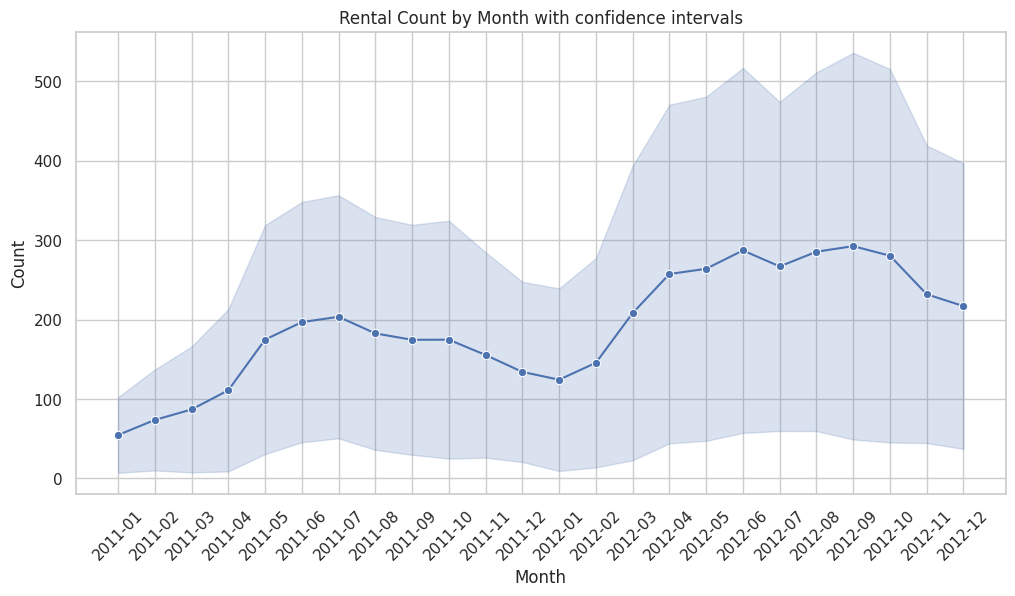

In [16]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='month_year', y='count', errorbar='sd', marker='o', markersize=6)
plt.title('Rental Count by Month with confidence intervals')
plt.xlabel('Month')
plt.ylabel('Count')
plt.xticks(rotation=45);


## Завдання 2: Порівняння стилів - Pandas vs Seaborn гістограма

**Завдання:**
Побудуйте гістограму розподілу температури двома способами - з Pandas та Seaborn - та порівняйте візуальний вигляд. Задайте однакову кількість бінів в цих візуалізаціях, відмінну від стандартної. В візуалізації Seaborn додайте параметр при побудові `kde=True`.

**Функція Seaborn: `sns.histplot()`**

Можна побудувати окремо два графіки. Але для тих, хто хоче складніше - побудуйте ці 2 графіки на 1 фігурі.

**Дайте відповідь на питання:**
1. Яка візуальна різниця між Pandas та Seaborn гістограмами?
2. Що за лінія додаткова на графіку в Seaborn? Як вона називається і як ви б її описали своїми словами?

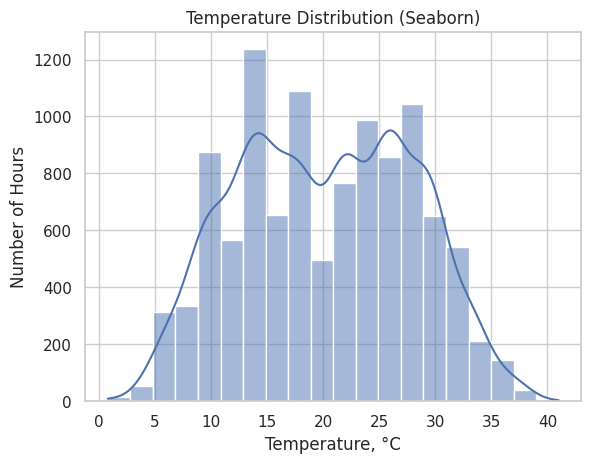

In [26]:
sns.histplot(data=df, x='temp', bins=20, kde=True)
plt.title('Temperature Distribution')
plt.xlabel('Temperature, °C')
plt.ylabel('Number of Hours');


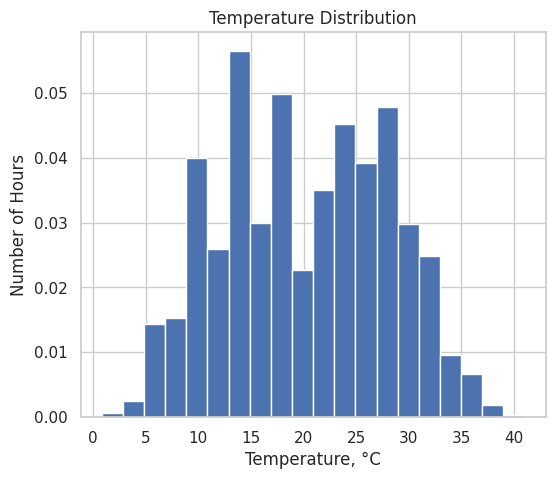

In [37]:
df['temp'].plot.hist(bins=20,
    figsize=(6,5),
    title='Temperature Distribution',
    xlabel='Temperature, °C',
    ylabel='Number of Hours'
);

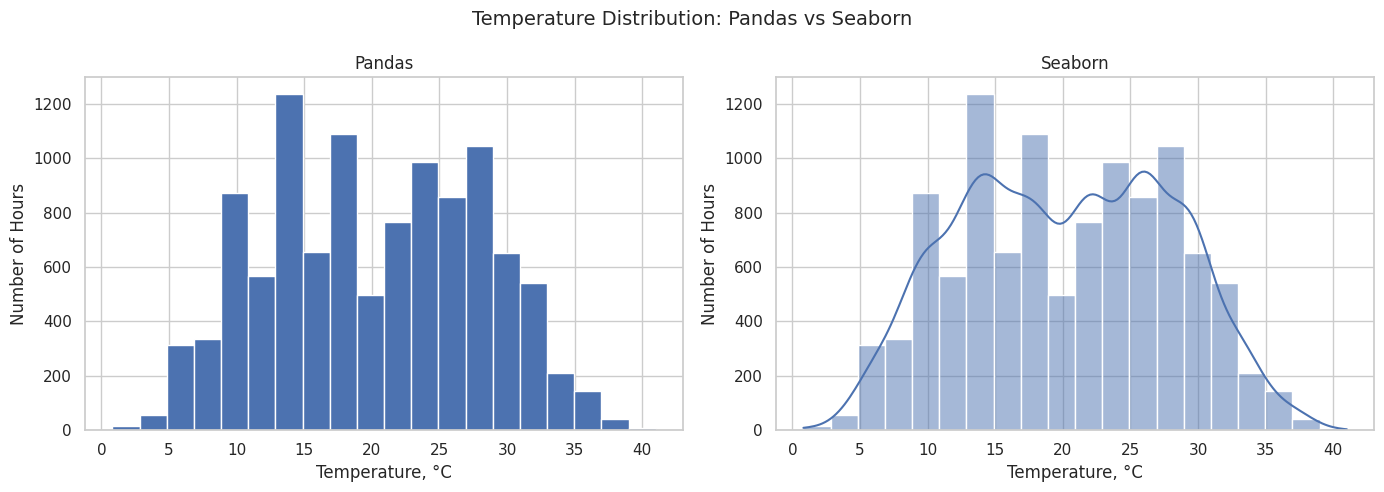

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Temperature Distribution: Pandas vs Seaborn', fontsize=14)

# Pandas
df['temp'].plot.hist(bins=20, ax=ax[0], edgecolor='white')
ax[0].set_title('Pandas')
ax[0].set_xlabel('Temperature, °C')
ax[0].set_ylabel('Number of Hours')

# Seaborn
sns.histplot(data=df, x='temp', bins=20, kde=True, ax=ax[1])
ax[1].set_title('Seaborn')
ax[1].set_xlabel('Temperature, °C')
ax[1].set_ylabel('Number of Hours')

plt.tight_layout()
plt.show()

**1. Візуальна різниця:**
- **Pandas** — простий стандартний вигляд: суцільні стовпці, мінімум оформлення.
- **Seaborn** — сучасніший стиль: м'якші кольори, напівпрозорі стовпці, сітка.
  Плюс додаткова лінія, що показує форму розподілу.
- Дані й кількість бінів однакові, тому висота стовпців та сама. Відрізняється лише оформлення.

**2. Додаткова лінія — це KDE (Kernel Density Estimate), оцінка щільності розподілу.**
Своїми словами: це гістограма. Плавна лінія показує форму розподілу без «сходинок» стовпців. Де лінія високо - бачимо високу кількість оренд, при температурі  10–30°C, а коли лінія дуже низько - відповідає за оренду в дуже холодні (<5°C) і дуже спекотні (>35°C) години дня.

## Завдання 3: Box Plot порівняння - Pandas vs Seaborn

**Завдання:**
Побудуйте box plot для кількості погодинних оренд велосипедів за погодними умовами з Pandas та Seaborn.

**Функція Seaborn: `sns.boxplot()`**

Можна побудувати окремо два графіки. Але для тих, хто хоче складніше - побудуйте ці 2 графіки на 1 фігурі.

Просунуте доповнення:
- підпишіть погодні умови їх інтерпретацією з опису даних в обох графіках

**Дайте відповідь на питання:**
- Яка візуальна різниця між Pandas та Seaborn бокс-плотами?

/tmp/ipykernel_4365/349126926.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xticklabels(weather_labels)


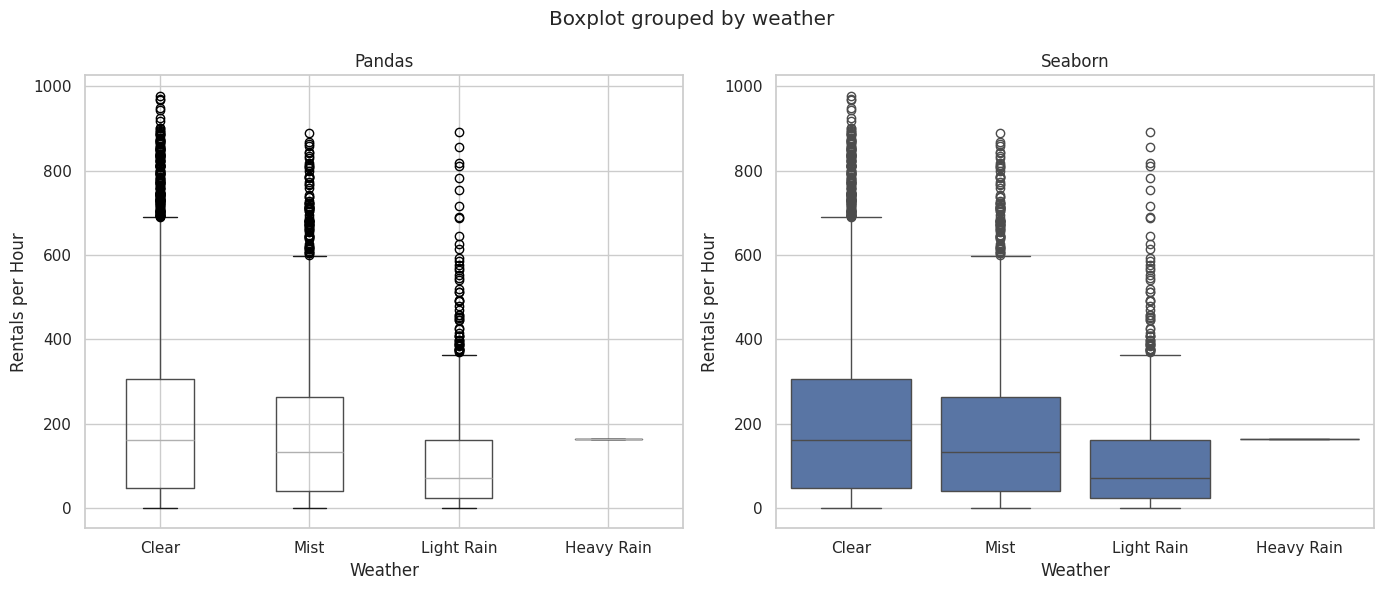

In [39]:
weather_labels = ['Clear', 'Mist', 'Light Rain', 'Heavy Rain']

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Hourly Rentals by Weather: Pandas vs Seaborn', fontsize=14)

# Pandas
df.boxplot(column='count', by='weather', ax=ax[0])
ax[0].set_title('Pandas')
ax[0].set_xlabel('Weather')
ax[0].set_ylabel('Rentals per Hour')
ax[0].set_xticklabels(weather_labels)

# Seaborn
sns.boxplot(data=df, x='weather', y='count', ax=ax[1])
ax[1].set_title('Seaborn')
ax[1].set_xlabel('Weather')
ax[1].set_ylabel('Rentals per Hour')
ax[1].set_xticklabels(weather_labels)

plt.tight_layout()
plt.show()

**Візуальна різниця між Pandas і Seaborn:**
- **Pandas** — простий вигляд: тонкі лінії, коробки без заливки, медіана іншим кольором, сітка за замовчуванням.
  Pandas автоматично додає зайвий заголовок «Boxplot grouped by weather», який треба прибирати.
- **Seaborn** — сучасніший вигляд: коробки з кольоровою заливкою, акуратніші викиди (ромбики).
  Підписи осей Seaborn бере з назв колонок автоматично.
- Дані однакові, тому медіани, коробки й викиди на обох графіках збігаються. Відрізняється лише оформлення.

<!-- - -->
## Завдання 4: Heatmap кореляційної матриці

**Завдання:**
Створіть із Seaborn кореляційну матрицю з забарвленням heatmap (колір відповідає величині значення в клітинці) числових змінних в наших даних з анотаціями значень.

**Дайте відповіді на питання по графіку:**
1. Які змінні найсильніше корелюють з загальною кількістю оренди (count)?
2. Яка кореляція між temp та atemp? Чому?
3. Які змінні мають негативну кореляцію?


In [47]:
df.head()

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,date,day,week,weekday_num,weekday,year,month,hour,month_year
datetime,,,,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,2011-01-01,1,52,5,Saturday,2011,1,0,2011-01
2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,2011-01-01,1,52,5,Saturday,2011,1,1,2011-01
2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2011-01-01,1,52,5,Saturday,2011,1,2,2011-01
2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,2011-01-01,1,52,5,Saturday,2011,1,3,2011-01
2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1,2011-01-01,1,52,5,Saturday,2011,1,4,2011-01


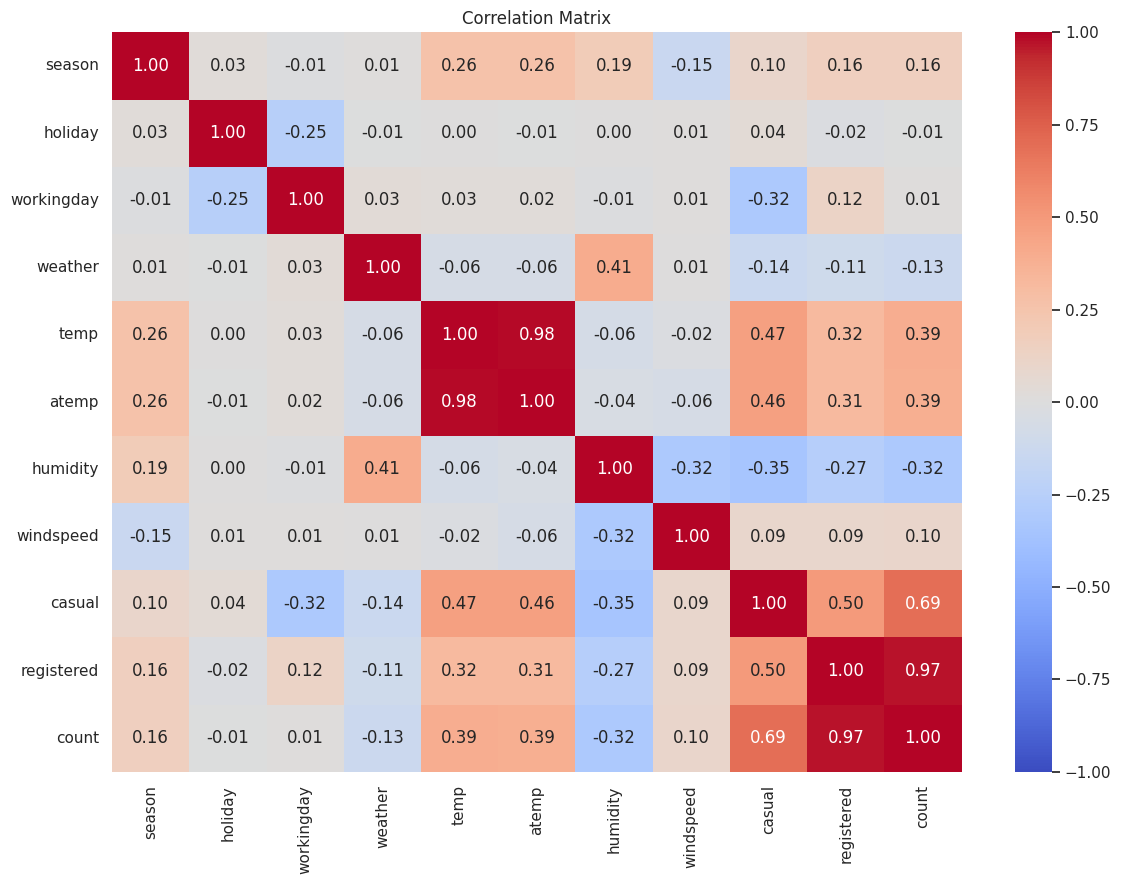

In [46]:
corr = df[['season', 'holiday', 'workingday', 'weather', 'temp', 'atemp',
            'humidity', 'windspeed', 'casual', 'registered', 'count']].corr()


plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

**1. Найсильніша кореляція з count:**
- **registered (0.97)** і **casual (0.69)**. Це складові самого count (count = casual + registered), тому висока кореляція очевидна.
- Серед зовнішніх факторів найсильніші — **temp і atemp (0.39)**: що тепліше, то більше оренд.
- Далі **humidity (−0.32)**: що вища вологість, то менше оренд.

**2. temp і atemp — 0.98**, тобто майже ідеальна позитивна кореляція.
atemp («відчувається як») розраховується з реальної температури temp, тому вони майже дублюють одна одну.
Для аналізу достатньо однієї з них.

**3. Негативна кореляція:**
- **humidity і count (−0.32)**, а також **humidity і casual (−0.35)**: у вологу погоду (дощ, туман) катаються менше, особливо випадкові користувачі.
- **workingday і casual (−0.32)**: випадкові користувачі катаються переважно у вихідні.
- **humidity і windspeed (−0.32)**: у вітряну погоду вологість нижча.
- **holiday і workingday (−0.25)**: святковий день за визначенням не робочий.
- **weather і count (−0.13)**: що гірша погода, то менше оренд, хоча зв'язок слабкий.

**Цікаве спостереження:** workingday майже не впливає на загальну кількість оренд (0.01),
але впливає на типи користувачів у протилежні боки: casual −0.32, registered +0.12.
Це підтверджує висновок попереднього завдання: зареєстровані їздять на роботу в будні, а випадкові — відпочивати у вихідні.

## Завдання 5: Violin Plot для глибокого аналізу розподілів

**Завдання:**
Створіть violin plot для аналізу розподілу оренди за кварталами.

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Що показує "товщина" violin plot?
2. В якому кварталі найбільша варіабельність оренди?
3. Яка перевага violin plot над звичайним box plot?


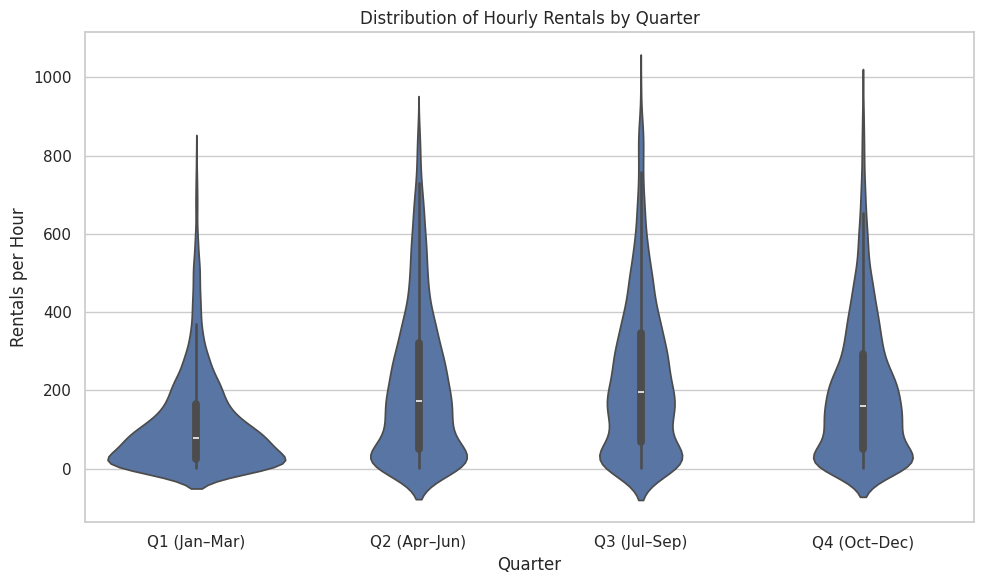

In [48]:
quarter_labels = ['Q1 (Jan–Mar)', 'Q2 (Apr–Jun)', 'Q3 (Jul–Sep)', 'Q4 (Oct–Dec)']

plt.figure(figsize=(10, 6))
ax = sns.violinplot(data=df, x='season', y='count')
ax.set_xticks(ax.get_xticks(), quarter_labels)
plt.title('Distribution of Hourly Rentals by Quarter')
plt.xlabel('Quarter')
plt.ylabel('Rentals per Hour')
plt.tight_layout()
plt.show()

**1. «Товщина» violin plot** показує, як часто трапляються значення.
Де «скрипка» широка, там багато годин з такою кількістю оренд, а де вузька — таких годин мало.

**2. Найбільша варіабельність** — у **Q3 (липень–вересень)**: найбільше std і найвища, найбільш «розтягнута» скрипка.
Улітку оренда коливається від майже 0 вночі до 900+ у години пік.
Найменша варіабельність — у **Q1**: узимку оренд мало, і вони зосереджені в низьких значеннях (широка частина внизу).

**3. Перевага violin plot над box plot:**
box plot показує лише медіану, квартилі й викиди, а violin plot показує ще й **форму розподілу**:
де значення скупчуються, чи є кілька піків.
Наприклад, два розподіли з однаковою коробкою можуть мати зовсім різну форму, і box plot цього не покаже, а violin plot покаже.

## Завдання 6 : Pairplot для мультиваріативного аналізу

**Завдання:**
Створіть pairplot для аналізу взаємозв'язків між ключовими змінними `'temp', 'humidity', 'windspeed', 'count'` . В якості візуальної розбивки за категоріями (параметр `hue`) додайте season (квартал).

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Між якими змінними спостерігається найсильніший лінійний зв'язок?
2. Яка характеристика найбільше відрізняється між кварталами?

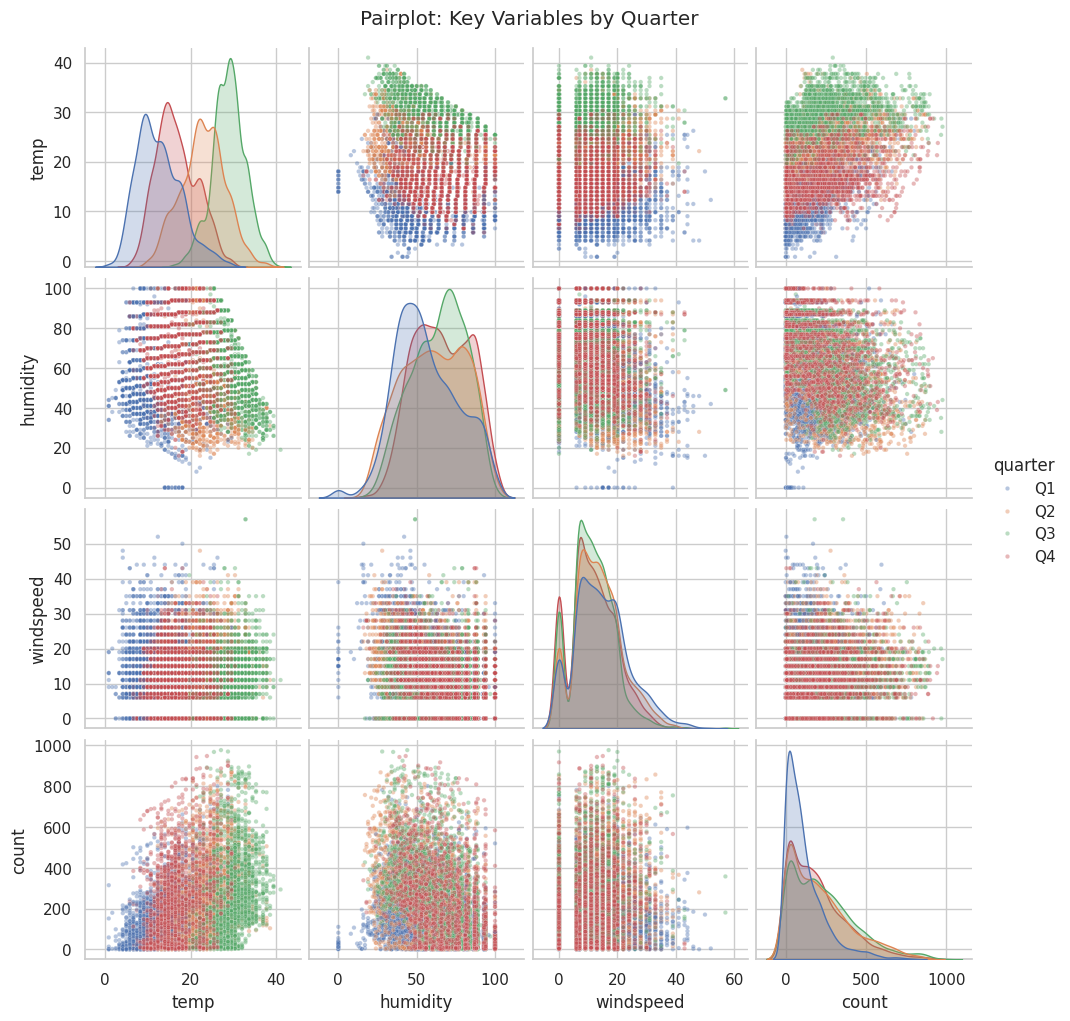

In [49]:
quarter_names = {1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4'}
df['quarter'] = df['season'].map(quarter_names)

sns.pairplot(
    df[['temp', 'humidity', 'windspeed', 'count', 'quarter']],
    hue='quarter',
    hue_order=['Q1', 'Q2', 'Q3', 'Q4'],
    plot_kws={'alpha': 0.4, 's': 10}
)
plt.suptitle('Pairplot: Key Variables by Quarter', y=1.02)
plt.show()

**1.** На більшості графіків точки утворюють суцільні хмари без чіткого напрямку, тобто сильних лінійних зв'язків між цими змінними немає.
Найпомітніший зв'язок — між **temp і count**: верхня межа хмари піднімається зі зростанням температури (кореляція 0.39 — помірний позитивний зв'язок).
Зв'язок нечіткий, бо кількість оренд сильно залежить ще й від години доби: вночі оренд мало при будь-якій температурі.
Інші пари (humidity, windspeed з count) — це розмиті хмари без чіткого нахилу, тобто зв'язок слабкий.

**2. Найбільше між кварталами відрізняється температура.**
На діагоналі (верхній лівий графік) розподіли temp чітко розсунуті:
Q1 ≈ 10°C (найхолодніший) → Q4 ≈ 15°C → Q2 ≈ 25°C → Q3 ≈ 30°C (найтепліший).

**Додаткові спостереження:**
Q4 (жовтень–грудень) тепліший за Q1 (січень–березень), тому й оренд у Q4 більше.

## Завдання 7: Joint Plot для детального аналізу двох змінних

**Завдання:**
Проаналізуйте залежність між температурою та орендою за допомогою joint plot. В якості візуальної розбивки за категоріями (параметр `hue`) додайте `workingday`.

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Що показують графіки по краях?
2. Чи є різниця у поведінці користувачів у робочий і неробочий день?

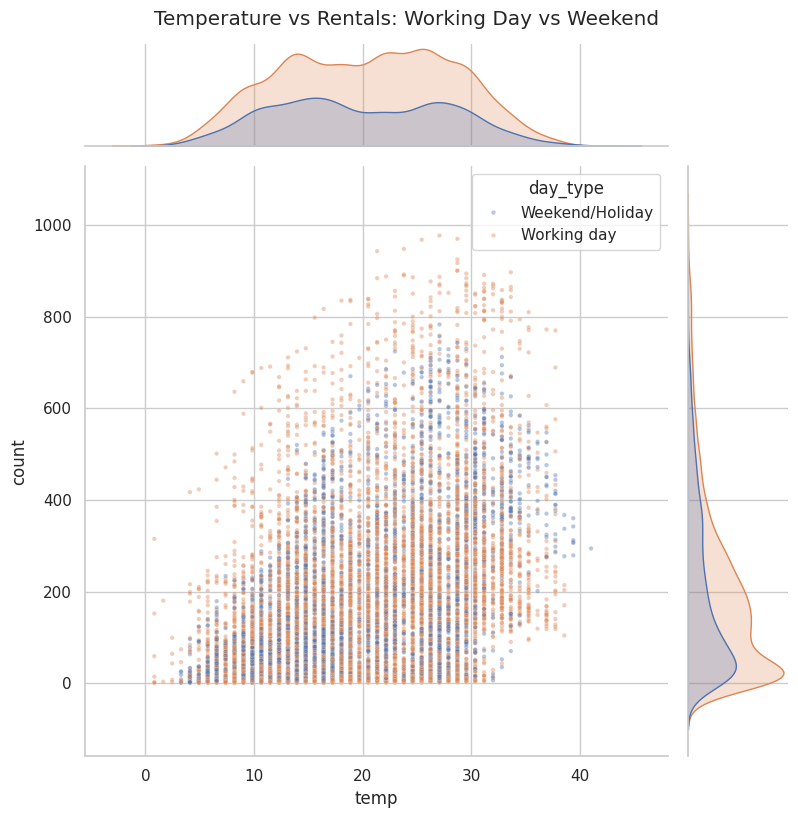

In [50]:
df['day_type'] = df['workingday'].map({1: 'Working day', 0: 'Weekend/Holiday'})

sns.jointplot(
    data=df, x='temp', y='count', hue='day_type',
    alpha=0.4, s=10, height=8
)
plt.suptitle('Temperature vs Rentals: Working Day vs Weekend', y=1.02)
plt.show()

**1. Графіки по краях** показують розподіл кожної змінної окремо:
- **зверху** — розподіл температури: найчастіше 10–30°C;
- **справа** — розподіл кількості оренд за годину: найчастіше 0–100, рідше 400+.
Кожен розподіл показаний окремо для робочих (помаранчевий) і неробочих (синій) днів.
Помаранчеві «горби» вищі, бо робочих днів більше.

**2. Різниця в поведінці є:**
- Залежність від температури однакова: в обидва типи днів що тепліше, то більше оренд.
- Але **найвищі значення (700–1000 оренд за годину) бувають майже тільки в робочі дні**. Це години пік, коли люди їдуть на роботу й з роботи.
- У неробочі дні пікових значень немає, оренда розподілена рівномірніше протягом дня.
- Отже, у будні велосипед — транспорт (різкі піки), а у вихідні — відпочинок (рівномірна оренда).

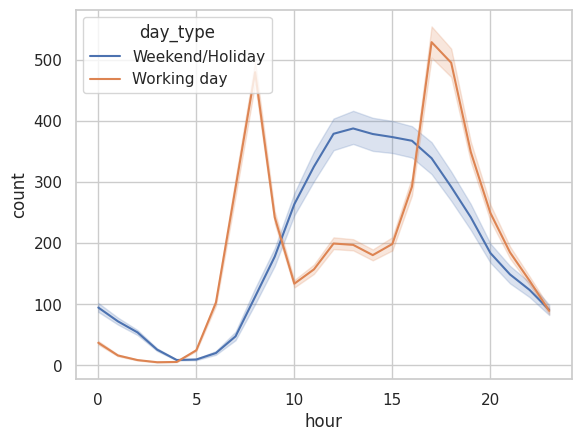

In [51]:
sns.lineplot(data=df, x='hour', y='count', hue='day_type')
plt.show()